# Troubleshooting Sufficiency Classification — baseline

Kaggle: https://www.kaggle.com/competitions/troubleshooting-sufficiency-classification-ml

Binary text classification: does a tech-support question contain enough info to start troubleshooting?
- `0` = sufficient, `1` = insufficient
- 64 labelled train questions, 50 test questions. Metric: F1 score.

This notebook: load → quick EDA → repeated stratified CV → baselines (majority, TF-IDF + logistic regression, frozen sentence embeddings + LR) → submission.

In [1]:
import random, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline, make_union
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

SEED = 42
random.seed(SEED); np.random.seed(SEED)

DATA = Path("data")
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")
print(train.shape, test.shape, sample.shape)
train.head()

(64, 3) (50, 2) (50, 2)


,id,text,sufficiency
0,ID1,Title: Outlook Inbox not updating\n\nQuestion:...,0
1,ID3,Title: Mac Mail - Outlook Exchange issues\n\nQ...,0
2,ID7,Title: How delete cache in Outlook\n\nQuestion...,1
3,ID8,Title: Favorites Section Missing from Outlook ...,0
4,ID9,Title: New Outlook - Cannot connect to server\...,0


## EDA

sufficiency
0 sufficient      42
1 insufficient    22
Name: count, dtype: int64


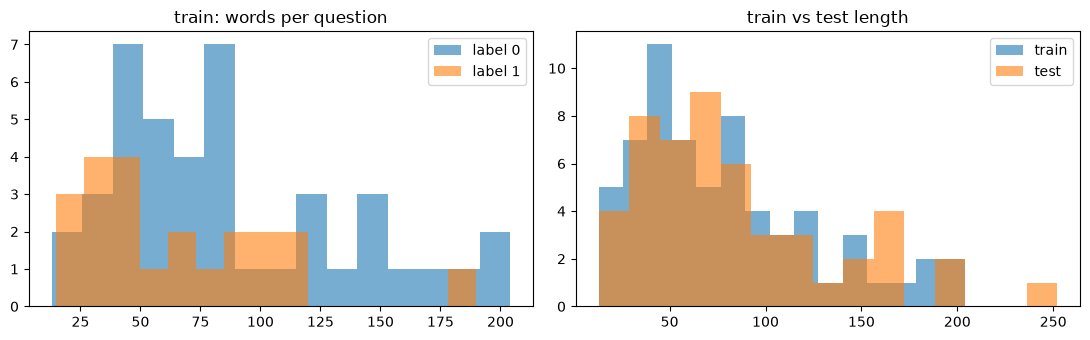

sufficiency              0            1
n_chars count    42.000000    22.000000
        mean    491.333333   399.318182
        std     277.555766   299.685770
        min      86.000000    76.000000
        25%     290.000000   206.250000
        50%     406.000000   301.000000
        75%     700.250000   521.750000
        max    1075.000000  1431.000000
n_words count    42.000000    22.000000
        mean     87.071429    66.000000
        std      50.460993    41.921696
        min      13.000000    15.000000
        25%      49.500000    34.750000
        50%      76.500000    53.500000
        75%     123.250000    93.500000
        max     204.000000   190.000000

In [2]:
print(train["sufficiency"].value_counts().rename({0: "0 sufficient", 1: "1 insufficient"}))

for df in (train, test):
    df["n_chars"] = df["text"].str.len()
    df["n_words"] = df["text"].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for lab, g in train.groupby("sufficiency"):
    ax[0].hist(g["n_words"], bins=15, alpha=0.6, label=f"label {lab}")
ax[0].set_title("train: words per question"); ax[0].legend()
ax[1].hist(train["n_words"], bins=15, alpha=0.6, label="train")
ax[1].hist(test["n_words"], bins=15, alpha=0.6, label="test")
ax[1].set_title("train vs test length"); ax[1].legend()
plt.tight_layout(); plt.show()

train.groupby("sufficiency")[["n_chars", "n_words"]].describe().T

In [3]:
# Read a few examples of each class
for lab in (0, 1):
    print(f"==================== label {lab} ====================")
    for t in train.loc[train.sufficiency == lab, "text"].sample(2, random_state=SEED):
        print(t[:700], "\n---")

==================== label 0 ====================
Title: Stop Smart Invert from auto-enabling on iPhone 18 Pro

Question:
To prevent Smart Invert from “mysteriously and automatically” enabling on an iPhone 18 Pro, do this: Settings > Accessibility > scroll down to the General section > Accessibility Shortcut > deselect Smart Invert. 
---
Title: Merge user account on-prem and 365 account using Powershell

Question:
Hello, We have a user called dan claton who has an on-prem AD username of Dclayton and was not in the sync OU. A technician then created a O365 account for a mailbox dan.clayton@ and this has now been used for over two years. Can we merge these entries so the user signs in with the on-prem details but still uses the O365 licence and mailbox? 
---
==================== label 1 ====================
Title: How delete cache in Outlook

Question:
Hi Team. How delete cache in Outlook client? Outlook options have one option for clean auto complete, but this option It's not what I nee

## Cross-validation setup

Only 64 rows, so a single split is very noisy: use 5-fold stratified CV repeated 5 times and report mean ± std.
Kaggle's "F1 Score" tag doesn't say binary vs macro, so both are printed (binary = F1 of class 1, "insufficient").

In [4]:
X, y = train["text"].values, train["sufficiency"].values
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
results = {}

def evaluate(name, make_model, X=X, y=y):
    """make_model: () -> fresh estimator with fit/predict. Returns out-of-fold predictions of the first repeat."""
    f1b, f1m = [], []
    for train_idx, val_idx in cv.split(X, y):
        m = make_model().fit(X[train_idx], y[train_idx])
        p = m.predict(X[val_idx])
        f1b.append(f1_score(y[val_idx], p, zero_division=0))
        f1m.append(f1_score(y[val_idx], p, average="macro", zero_division=0))
    results[name] = dict(f1_binary=np.mean(f1b), f1_binary_std=np.std(f1b),
                         f1_macro=np.mean(f1m), f1_macro_std=np.std(f1m))
    print(f"{name:35s} binary F1 {np.mean(f1b):.3f} ± {np.std(f1b):.3f}   macro F1 {np.mean(f1m):.3f} ± {np.std(f1m):.3f}")

## Baselines

In [5]:
evaluate("majority (all 0)", lambda: DummyClassifier(strategy="most_frequent"))
evaluate("all insufficient (all 1)", lambda: DummyClassifier(strategy="constant", constant=1))

def tfidf_lr(C=1.0):
    return make_pipeline(
        make_union(
            TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True),
            TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
        ),
        LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED),
    )

for C in (0.3, 1, 3, 10):
    evaluate(f"tfidf word+char LR C={C}", lambda C=C: tfidf_lr(C))

majority (all 0)                    binary F1 0.000 ± 0.000   macro F1 0.396 ± 0.013


all insufficient (all 1)            binary F1 0.510 ± 0.038   macro F1 0.255 ± 0.019


tfidf word+char LR C=0.3            binary F1 0.156 ± 0.193   macro F1 0.452 ± 0.103


tfidf word+char LR C=1              binary F1 0.178 ± 0.176   macro F1 0.466 ± 0.094


tfidf word+char LR C=3              binary F1 0.180 ± 0.179   macro F1 0.469 ± 0.096


tfidf word+char LR C=10             binary F1 0.168 ± 0.179   macro F1 0.462 ± 0.098


## Frozen sentence embeddings + logistic regression

Mean-pooled embeddings from a small pretrained encoder (downloads from Hugging Face on first run).
Embeddings are computed once for train+test; only the LR is fit inside CV.

In [6]:
import torch
from transformers import AutoTokenizer, AutoModel

torch.manual_seed(SEED)
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

def embed(texts, model_name="sentence-transformers/all-mpnet-base-v2", batch_size=16, max_length=512):
    tok = AutoTokenizer.from_pretrained(model_name)
    enc = AutoModel.from_pretrained(model_name).to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            b = tok(list(texts[i:i + batch_size]), padding=True, truncation=True,
                    max_length=max_length, return_tensors="pt").to(DEVICE)
            h = enc(**b).last_hidden_state
            mask = b["attention_mask"].unsqueeze(-1).float()
            e = (h * mask).sum(1) / mask.sum(1)
            out.append(torch.nn.functional.normalize(e, dim=1).cpu().numpy())
    return np.vstack(out)

EMB_MODEL = "sentence-transformers/all-mpnet-base-v2"
emb_all = embed(np.concatenate([X, test["text"].values]), EMB_MODEL)
E_train, E_test = emb_all[:len(X)], emb_all[len(X):]
print(E_train.shape, E_test.shape)

for C in (0.1, 1, 10):
    evaluate(f"mpnet emb LR C={C}",
             lambda C=C: LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED),
             X=E_train)

/Users/home/workspace/School/ML/competition/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1121 16:40:09.227000 64133 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 20875.01it/s]

(64, 768) (50, 768)
mpnet emb LR C=0.1                  binary F1 0.431 ± 0.191   macro F1 0.554 ± 0.158
mpnet emb LR C=1                    binary F1 0.426 ± 0.221   macro F1 0.552 ± 0.174


mpnet emb LR C=10                   binary F1 0.454 ± 0.186   macro F1 0.586 ± 0.147


## Results

In [7]:
res = pd.DataFrame(results).T.sort_values("f1_binary", ascending=False)
res.round(3)

,f1_binary,f1_binary_std,f1_macro,f1_macro_std
all insufficient (all 1),0.510,0.038,0.255,0.019
mpnet emb LR C=10,0.454,0.186,0.586,0.147
mpnet emb LR C=0.1,0.431,0.191,0.554,0.158
mpnet emb LR C=1,0.426,0.221,0.552,0.174
tfidf word+char LR C=3,0.180,0.179,0.469,0.096
tfidf word+char LR C=1,0.178,0.176,0.466,0.094
tfidf word+char LR C=10,0.168,0.179,0.462,0.098
tfidf word+char LR C=0.3,0.156,0.193,0.452,0.103
majority (all 0),0.000,0.000,0.396,0.013


## Submission

Fit the chosen model on all 64 training questions and predict the 50 test questions.
Change `best` to whichever row wins above (pick by CV, not by public leaderboard).

In [8]:
best = "mpnet emb LR C=10"   # <- update after looking at the results table
model = LogisticRegression(C=10, class_weight="balanced", max_iter=2000, random_state=SEED).fit(E_train, y)
pred = model.predict(E_test)

sub = pd.DataFrame({"id": test["id"], "sufficiency": pred.astype(int)})
assert list(sub.columns) == list(sample.columns) and set(sub.id) == set(sample.id)
print(sub["sufficiency"].value_counts())
sub.to_csv("submission_baseline.csv", index=False)
print("wrote submission_baseline.csv  | model:", best, "| CV:", results[best])

sufficiency
0    36
1    14
Name: count, dtype: int64
wrote submission_baseline.csv  | model: mpnet emb LR C=10 | CV: {'f1_binary': np.float64(0.4542481962481962), 'f1_binary_std': np.float64(0.1859780189517267), 'f1_macro': np.float64(0.5862607746570595), 'f1_macro_std': np.float64(0.14684929131501764)}
